# 02 — Yes/no vs multiple choice, and mirages that guessing or priors can't explain

**Question.** Is the mirage signal an artefact of (a) yes/no chance agreement or (b) questions answerable from text priors ("gaming")? Compare VQA-RAD (yes/no, k=2) with MedXpertQA-MM (5 options, first 400 questions), same model (Qwen3-VL-4B), same pipeline as notebook 01.

**Two fixes to the paper's label.**
1. **`commit`** = the without-image reply never acknowledges the missing image (`label != admit`). It does **not** use answer agreement or correctness, so it can't be inflated by chance matches.
2. **Prior strength** = text-only, honest prompt ("no image is available… reply with only the answer"), probability of the correct answer from the first-token logprobs, averaged over the 5 paraphrases (`miragelab/prior.py`). Questions with prior ≤ chance (1/k) give nothing to exploit: a commit there can't be benchmark gaming.

In [1]:
import sys, os, subprocess, numpy as np, pandas as pd, matplotlib.pyplot as plt
import os; BENCH = os.environ.get('MIRAGE_ROOT', '..'); sys.path.insert(0, '..')  # BENCH: data root with runs/
from miragelab import analysis as A
print(subprocess.run([sys.executable, '-m', 'pytest', '-q', '../tests'], capture_output=True, text=True, cwd='..').stdout[-120:])
RUNS = {'yes/no (VQA-RAD)': BENCH + '/runs/full', 'MC-5 (MedXpertQA-MM)': BENCH + '/runs/mcq400'}
F = {k: A.with_prior(v) for k, v in RUNS.items()}
for k, f in F.items():
    f['chance'] = 1 / f.k
    print(k, f.shape, '| k =', f.k.unique(), '| prior coverage', round(f.coverage.mean(), 3))

..                               [100%]
42 passed in 9.79s

yes/no (VQA-RAD) (5950, 24) | k = [2] | prior coverage 0.997
MC-5 (MedXpertQA-MM) (2000, 24) | k = [5 6] | prior coverage 0.994


## 1. Behaviour by format
**Methods.** Accuracy with/without image vs chance (Wilson 95% CIs). Label rates. For commits: how often the with- and without-image answers agree, vs the agreement expected by chance from the answer marginals (Cohen's κ) — the paper's mirage label requires agreement.

format,yes/no (VQA-RAD),MC-5 (MedXpertQA-MM)
records,5950.000,2000.000
chance,0.500,0.200
acc_with,0.654,0.279
acc_without,0.543,0.248
admit,0.881,0.020
commit,0.119,0.980
mirage_paper,0.115,0.360
mirage_fixed,0.055,0.358
commit_agree_obs,0.673,0.526
commit_agree_chance,0.449,0.251


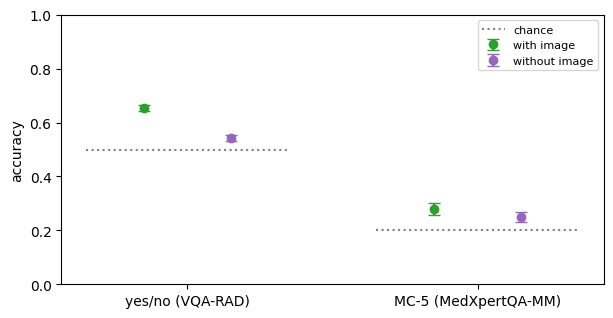

In [2]:
rows = []
for k, f in F.items():
    w = f.with_correct.dropna(); n = f.no_correct.dropna(); c = f[f.commit]
    obs, exp, kap = A.agreement(c.with_pred, c.no_pred)
    rows.append(dict(format=k, records=len(f), chance=f.chance.iloc[0],
        acc_with=A.wilson(int(w.sum()), len(w))[0], acc_without=A.wilson(int(n.sum()), len(n))[0],
        admit=(f.label == 'admit').mean(), commit=f.commit.mean(),
        mirage_paper=(f.label_paper == 'mirage').mean(), mirage_fixed=(f.label == 'mirage').mean(),
        commit_agree_obs=obs, commit_agree_chance=exp, kappa=kap))
T = pd.DataFrame(rows).set_index('format').T.round(3); display(T)
fig, ax = plt.subplots(figsize=(7, 3.5)); x = np.arange(len(F))
for i, (k, f) in enumerate(F.items()):
    for off, col, lab in [(-.15, 'with_correct', 'with image'), (.15, 'no_correct', 'without image')]:
        s = f[col].dropna(); p, lo, hi = A.wilson(int(s.sum()), len(s))
        ax.errorbar(i + off, p, yerr=[[p - lo], [hi - p]], fmt='o', capsize=4, c='tab:green' if off < 0 else 'tab:purple', label=lab if i == 0 else None)
    ax.hlines(f.chance.iloc[0], i - .35, i + .35, colors='grey', linestyles=':', label='chance' if i == 0 else None)
ax.set_xticks(x, list(F)); ax.set_ylabel('accuracy'); ax.set_ylim(0, 1); ax.legend(fontsize=8); plt.show()

In [3]:
for k, f in F.items():
    print(f'===== {k}: commit examples on prior<=chance questions')
    q = f.groupby('uid').p_correct.mean(); low = set(q[q <= f.chance.iloc[0]].index)
    for _, r in f[f.commit & f.uid.isin(low)].sample(3, random_state=0).iterrows():
        print('Q:', r.question[:200], '| GT:', r['gt'], '| prior p_correct %.2f' % r.p_correct, '\n  NO-IMG:', r.no_resp[-300:].replace('\n', ' '), '\n')

===== yes/no (VQA-RAD): commit examples on prior<=chance questions
Q: Is the patient in a lying down position? | GT: yes | prior p_correct 0.56 
  NO-IMG: ill typically show symmetrical positioning of the thoracic or abdominal organs, with no signs of gravity-induced displacement or posture-related distortion.  Given that this is a radiology image and the standard clinical practice for such exams is to have the patient lying down, I conclude:  [[Yes]] 

Q: Is the patient lying supine? | GT: yes | prior p_correct 0.12 
  NO-IMG: bsence of significant rotation or obliquity. If the patient’s spine appears straight and the limbs are symmetrically positioned (e.g., arms at sides, legs extended), this further supports supine positioning.  Therefore, based on the visual evidence in the image, the patient is lying supine.  [[Yes]] 

Q: Is IV contrast applied in this CT scan? | GT: yes | prior p_correct 0.01 
  NO-IMG: ncreased attenuation. - There is no evidence of “no contrast” — the image do

**Results.** Yes/no: 65% with image vs 54% without (chance 50%); 88% of no-image replies admit the missing image; commits 12%. MC-5: 28% with vs 25% without (chance 20%); **only 2% admit — 98% commit**, because the paper's MC prompt says "You MUST select exactly one answer". Commits agree with the with-image answer 67% (yes/no) vs 45% expected by chance, κ = 0.41; MC 53% vs 25%, κ = 0.37. 9% of MC with-image requests failed (multi-image prompts over the length limit) and count as missing.

**Discussion.** (1) On yes/no, about two-thirds of the agreement the paper's mirage label requires is chance. (2) MedXpertQA-MM can't separate mirage from honesty on a 4B: near chance even with the image, and the prompt removes the option to admit. Format and prompt decide the mirage rate more than the model does.

## 2. How answerable is each question without the image?
**Methods.** Per-question prior = mean text-only p(correct) over 5 paraphrases. Dotted line = chance.

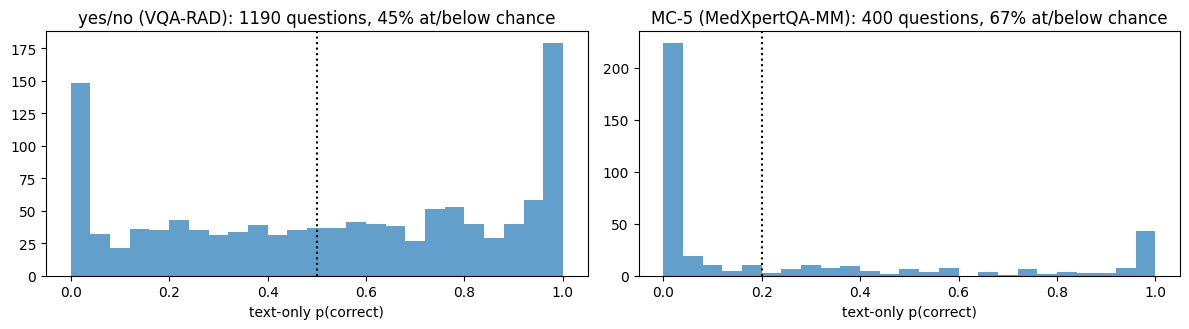

In [4]:
fig, axs = plt.subplots(1, len(F), figsize=(12, 3.4))
for ax, (k, f) in zip(axs, F.items()):
    q = f.groupby('uid').p_correct.mean()
    ax.hist(q, bins=25, color='tab:blue', alpha=.7); ax.axvline(f.chance.iloc[0], c='k', ls=':')
    ax.set(title=f'{k}: {len(q)} questions, {(q <= f.chance.iloc[0]).mean():.0%} at/below chance', xlabel='text-only p(correct)')
plt.tight_layout(); plt.show()

## 3. Headline: commit rate vs prior strength
**Methods.** Per record, bin the question's prior: below chance, then the range chance→1 split in thirds (low · mid · high), so bins mean the same thing for k=2 and k=5. Commit rate per bin with Wilson CIs. **Gaming predicts** commit rate rising with prior (model answers blind where it can get away with it). **A prior-independent mirage predicts** a flat line — including the below-chance bin, where committing is actively harmful.

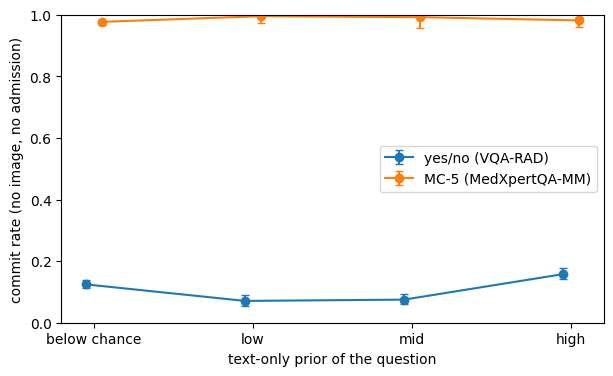

,sum,size,rate,lo,hi,format
prior_bin,,,,,,
below chance,336,2700,0.124,0.113,0.137,yes/no (VQA-RAD)
low,57,805,0.071,0.055,0.091,yes/no (VQA-RAD)
mid,66,880,0.075,0.059,0.094,yes/no (VQA-RAD)
high,247,1565,0.158,0.141,0.177,yes/no (VQA-RAD)
below chance,1309,1340,0.977,0.967,0.984,MC-5 (MedXpertQA-MM)
low,209,210,0.995,0.974,0.999,MC-5 (MedXpertQA-MM)
mid,124,125,0.992,0.956,0.999,MC-5 (MedXpertQA-MM)
high,319,325,0.982,0.960,0.992,MC-5 (MedXpertQA-MM)


In [5]:
fig, ax = plt.subplots(figsize=(7, 4)); out = []
for k, f in F.items():
    ch = f.chance.iloc[0]; qp = f.groupby('uid').p_correct.transform('mean')
    f['prior_bin'] = pd.cut(qp, [0, ch, ch + (1 - ch) / 3, ch + 2 * (1 - ch) / 3, 1.0001], right=False, labels=['below chance', 'low', 'mid', 'high'])
    g = f.groupby('prior_bin', observed=False).commit.agg(['sum', 'size'])
    ci = np.array([A.wilson(int(s), int(n)) for s, n in zip(g['sum'], g['size'])])
    ax.errorbar(np.arange(4) + (0.05 if 'MC' in k else -.05), ci[:, 0], yerr=[ci[:, 0] - ci[:, 1], ci[:, 2] - ci[:, 0]], marker='o', capsize=3, label=k)
    out.append(g.assign(rate=ci[:, 0], lo=ci[:, 1], hi=ci[:, 2], format=k))
ax.set_xticks(range(4), ['below chance', 'low', 'mid', 'high']); ax.set(xlabel='text-only prior of the question', ylabel='commit rate (no image, no admission)', ylim=(0, 1)); ax.legend(); plt.show()
display(pd.concat(out).round(3))

**Results.** Yes/no commit rate by text-only prior: below chance 12.4% [11.3, 13.7] · low 7.1% · mid 7.5% · high 15.8% [14.1, 17.7]. MC: 97.7–99.5% in every bin.

**Discussion.** Not monotonic in the prior, and 12% even where the text-only prior is worse than chance — blind answering isn't only benchmark gaming. There is a modest rise at high prior (16% vs 12%), so some of it is. MC gives no signal: the model commits regardless.

## 4. Is `commit` linearly readable before the reply — in both formats, and on prior-free questions?
**Methods.** Extracted subset per format (all commits, admits sampled). Probes as in notebook 01, target = commit (1) vs admit (0), grouped 5-fold by base question, balanced accuracy. **D** = without-image pre-answer state; **E** = with − without pre-answer; **B** = paper's Diff (text_mean incl. reply); **C** = without-image text_mean (echo check). Each on all questions and on prior ≤ chance only. B-shuf = shuffled labels. Every 4th saved layer to keep CPU time down.

In [6]:
res = []
for k, run in RUNS.items():
    if not os.path.exists(run + '/acts/meta.json'): print(k, 'no activations extracted — skipped'); continue
    df, acts, meta = A.load(run); L = meta['layers']
    pr = F[k].groupby('uid').p_correct.mean(); ch = F[k].chance.iloc[0]
    df['commit'] = df.label != 'admit'; df['prior_free'] = df.uid.map(pr) <= ch
    print(k, 'extracted', len(df), '| commit', int(df.commit.sum()), '| prior-free commit', int((df.commit & df.prior_free).sum()))
    for subset_name, m in [('all', np.ones(len(df), bool)), ('prior<=chance', df.prior_free.values)]:
        idx = np.where(m)[0]; y = df.commit.values[idx].astype(int); g = A.leak_groups(df.uid.values[idx], df.question.map(A.norm_text).values[idx])
        if min(y.sum(), (1 - y).sum()) < 10: print('  skip', subset_name, 'too few'); continue
        for j in range(1, len(L), 4):   # every 4th saved layer (CPU budget)
            W, N, LP, TM = 0, 1, 0, 1
            X = {'D no-img pre-answer': acts[idx, N, LP, j], 'E diff pre-answer': acts[idx, W, LP, j].astype('f4') - acts[idx, N, LP, j],
                 'B diff text_mean (paper)': acts[idx, W, TM, j].astype('f4') - acts[idx, N, TM, j], 'C no-img text_mean (echo)': acts[idx, N, TM, j]}
            for name, x in X.items():
                res.append((k, subset_name, name, L[j], *A.probe_cv(x, y, g)))
            res.append((k, subset_name, 'B-shuf', L[j], *A.probe_cv(X['B diff text_mean (paper)'], y, g, shuffle_labels=True)))
res = pd.DataFrame(res, columns=['format', 'subset', 'probe', 'layer', 'bacc', 'sd'])
res.groupby(['format', 'subset', 'probe']).bacc.max().unstack().round(3)

yes/no (VQA-RAD) extracted 1800 | commit 706 | prior-free commit 336
MC-5 (MedXpertQA-MM) no activations extracted — skipped


probe                           B diff text_mean (paper)  B-shuf  \
format           subset                                            
yes/no (VQA-RAD) all                               0.904   0.494   
                 prior<=chance                     0.886   0.520   

probe                           C no-img text_mean (echo)  \
format           subset                                     
yes/no (VQA-RAD) all                                0.917   
                 prior<=chance                      0.895   

probe                           D no-img pre-answer  E diff pre-answer  
format           subset                                                 
yes/no (VQA-RAD) all                          0.759              0.716  
                 prior<=chance                0.717              0.709

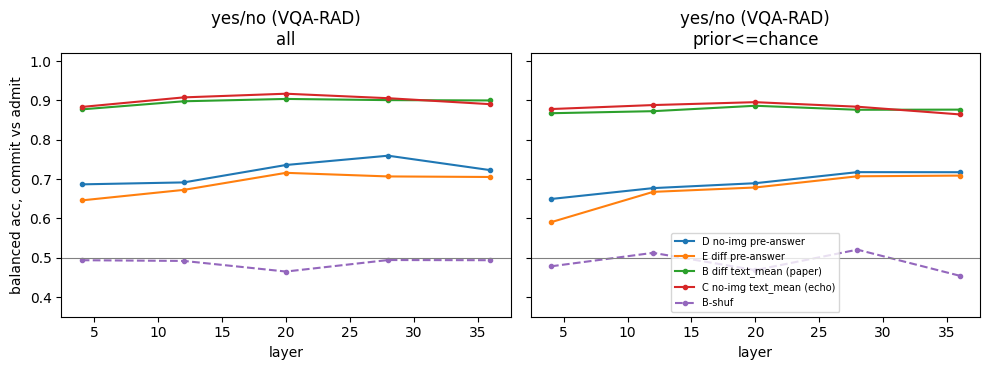

In [7]:
keys = [(f, s) for f in RUNS for s in ['all', 'prior<=chance'] if ((res.format == f) & (res.subset == s)).any()]
fig, axs = plt.subplots(1, len(keys), figsize=(5 * len(keys), 3.8), sharey=True)
for ax, (fm, sb) in zip(np.atleast_1d(axs), keys):
    for name, d in res[(res.format == fm) & (res.subset == sb)].groupby('probe', sort=False):
        ax.plot(d.layer, d.bacc, marker='o', ms=3, label=name, ls='--' if 'shuf' in name else '-')
    ax.axhline(.5, c='grey', lw=.8); ax.set(title=f'{fm}\n{sb}', xlabel='layer', ylim=(.35, 1.02))
np.atleast_1d(axs)[0].set_ylabel('balanced acc, commit vs admit'); np.atleast_1d(axs)[-1].legend(fontsize=7); plt.tight_layout(); plt.show()

### 4b. Geometry: does the commit region follow the prior?
**Methods.** PHATE (and PCA for the linear view) of without-image pre-answer states at the best D layer, per format. Left: colour = commit/admit. Right: colour = the question's text-only prior (continuous). If commit-space and prior-space line up, 'mirage' is prior-driven; if not, it is its own axis. PHATE is the right lens here because the prior is a continuous variable and we are asking whether states form a gradient along it.

~/lab/benches/mats-nanda/.venv/lib/python3.10/site-packages/graphtools/graphs.py:810: RuntimeWarning: Detected zero distance between 31 pairs of samples. Consider removing duplicates to avoid errors in downstream processing.
  warnings.warn(


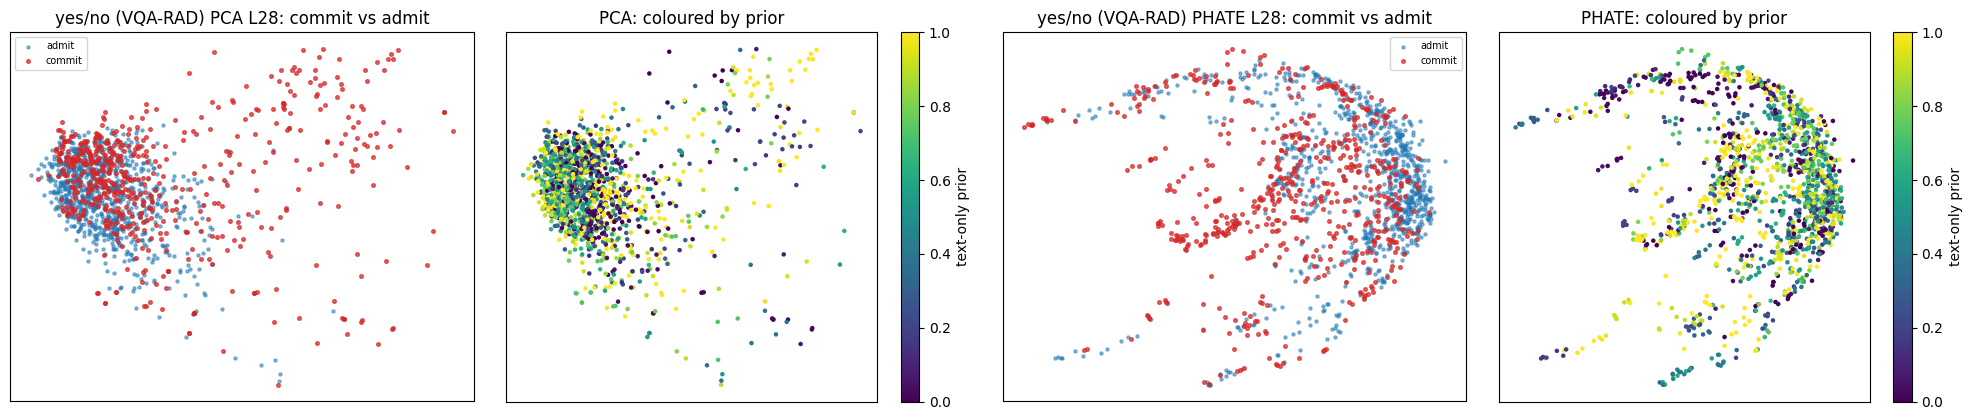

In [8]:
for k, run in RUNS.items():
    if not os.path.exists(run + '/acts/meta.json') or not (res.format == k).any(): continue
    df, acts, meta = A.load(run); L = meta['layers']; pr = F[k].groupby('uid').p_correct.mean()
    d = res[(res.format == k) & (res.subset == 'all') & (res.probe == 'D no-img pre-answer')]
    j = L.index(int(d.layer.values[d.bacc.values.argmax()]))
    rng = np.random.default_rng(0); sel = np.sort(rng.choice(len(df), min(1500, len(df)), replace=False))
    X = np.asarray(acts[sel, 1, 0, j], 'f4'); com = (df.label.values[sel] != 'admit'); prior = df.uid.map(pr).values[sel]
    fig, axs = plt.subplots(1, 4, figsize=(20, 4.3))
    for row, meth in enumerate(['pca', 'phate']):
        Z = A.embed(X, meth)
        a = axs[2 * row]; a.scatter(Z[~com, 0], Z[~com, 1], s=5, c='tab:blue', alpha=.5, label='admit'); a.scatter(Z[com, 0], Z[com, 1], s=7, c='tab:red', alpha=.7, label='commit')
        a.set_title(f'{k} {meth.upper()} L{L[j]}: commit vs admit'); a.legend(fontsize=7)
        b = axs[2 * row + 1]; sc = b.scatter(Z[:, 0], Z[:, 1], s=5, c=prior, cmap='viridis', vmin=0, vmax=1); plt.colorbar(sc, ax=b, label='text-only prior')
        b.set_title(f'{meth.upper()}: coloured by prior')
    for a in axs: a.set_xticks([]); a.set_yticks([])
    plt.tight_layout(); plt.show()

## 5. Discussion

- **Yes/no inflates the paper's label:** κ = 0.41 — most same-answer agreement on commits is chance.
- **The paper's MC prompt forbids admitting,** so on MedXpertQA-MM 98% of no-image replies commit; with 28% with-image accuracy the set tells us about the prompt, not about mirage vs honesty.
- **Prior control (yes/no):** commit rate 12% on questions whose text-only prior is below chance; modest rise to 16% at high prior. Mostly not gaming.
- **Encoded before speaking, prior-controlled** (leak-group folds): pre-answer probe D = 0.76 on all questions, **0.72 on prior ≤ chance questions**. Paper-style B/C ≈ 0.89–0.92 are echo-inflated (C ≈ B).
- **Geometry:** in PCA and PHATE the commit region does not follow the prior colouring.
- **Decision:** move the main test to open-ended SLAKE (notebooks 03–05).